In [1]:
pip install matplotlib-venn --break-system-packages

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for matplotlib-venn: filename=matplotlib_venn-1.1.2-py3-none-any.whl size=45440 sha256=fcebc8aaeb64aaf2bc2838e50c7e7a175cdcfceb04dc15630f35daaa5bd004b1
  Stored in directory: c:\users\hp\appdata\local\pip\cache\wheels\c4\16\4a\93374cd955bbe0553a8ce74db7f0fbd5fcc876e19fb78bd601
Successfully built matplotlib-venn
Note: you may need to restart the kernel to use updated packages.


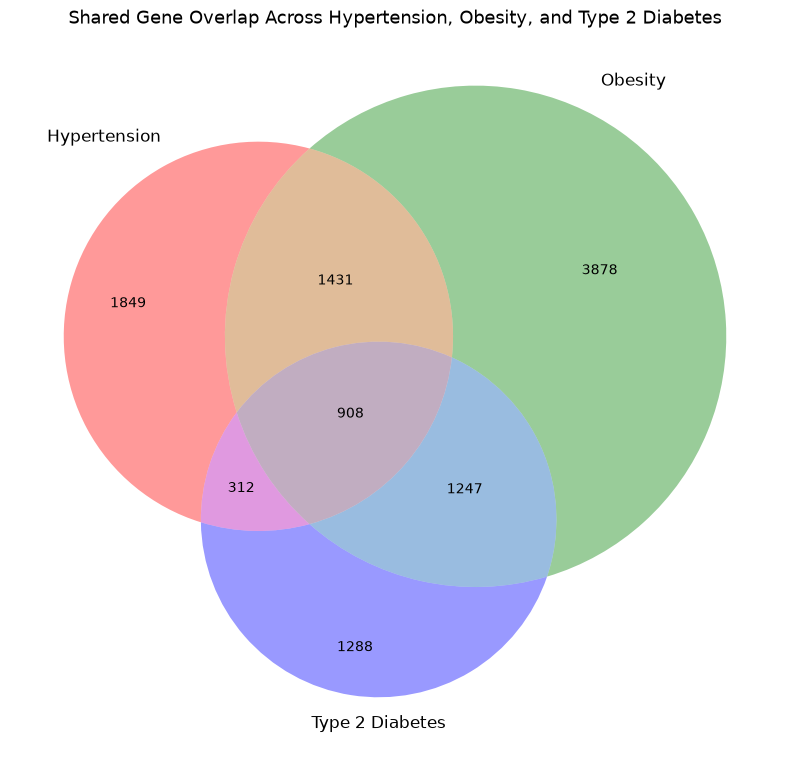

In [1]:
import pandas as pd
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

hyp_table = pd.read_csv(r"C:\tri_disease_project\data\processed\hypertension_master_filtered.csv")
obesity_table = pd.read_csv(r"C:\tri_disease_project\data\processed\obesity_master_filtered.csv")
t2d_table = pd.read_csv(r"C:\tri_disease_project\data\processed\t2d_master_filtered.csv")

hyp_genes = set(hyp_table['hgnc_symbol'])
obesity_genes = set(obesity_table['hgnc_symbol'])
t2d_genes = set(t2d_table['hgnc_symbol'])

fig, ax = plt.subplots(figsize=(8, 8))
venn3([hyp_genes, obesity_genes, t2d_genes], set_labels=('Hypertension', 'Obesity', 'Type 2 Diabetes'), ax=ax)
plt.title("Shared Gene Overlap Across Hypertension, Obesity, and Type 2 Diabetes", fontsize=13)
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig1_venn_diagram.png", dpi=300, bbox_inches='tight')
plt.show()

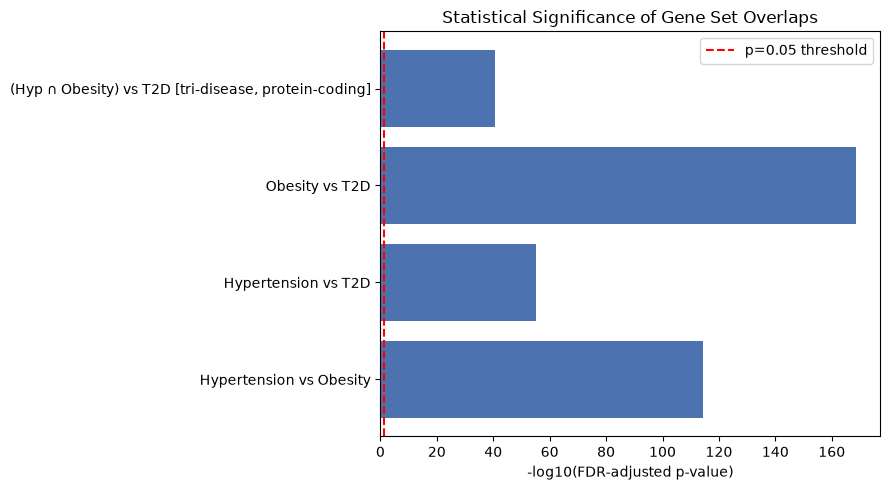

In [3]:
import numpy as np

results_df = pd.read_csv(r"C:\tri_disease_project\data\processed\phase3_hypergeometric_results.csv")
results_df['neg_log_p'] = -np.log10(results_df['p_adj_fdr'].replace(0, 1e-300))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(results_df['Comparison'], results_df['neg_log_p'], color='#4C72B0')
ax.set_xlabel('-log10(FDR-adjusted p-value)')
ax.set_title('Statistical Significance of Gene Set Overlaps')
ax.axvline(x=-np.log10(0.05), color='red', linestyle='--', label='p=0.05 threshold')
ax.legend()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig2_hypergeometric_significance.png", dpi=300, bbox_inches='tight')
plt.show()

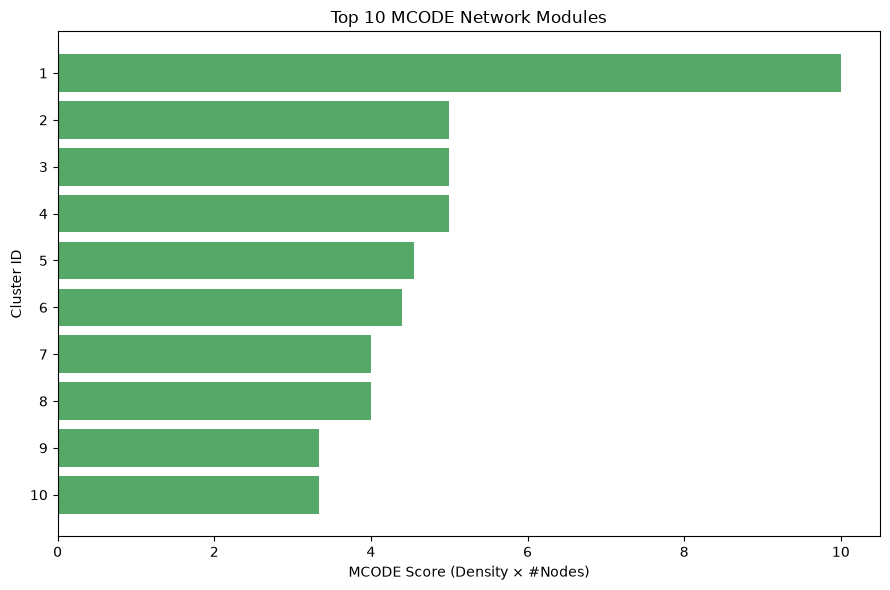

In [4]:
mcode_df = pd.read_csv(r"C:\tri_disease_project\results\tables\mcode_clusters_mapped.csv")
top_clusters = mcode_df.sort_values('score', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_clusters['cluster'].astype(str), top_clusters['score'], color='#55A868')
ax.set_xlabel('MCODE Score (Density × #Nodes)')
ax.set_ylabel('Cluster ID')
ax.set_title('Top 10 MCODE Network Modules')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig4_mcode_modules.png", dpi=300, bbox_inches='tight')
plt.show()

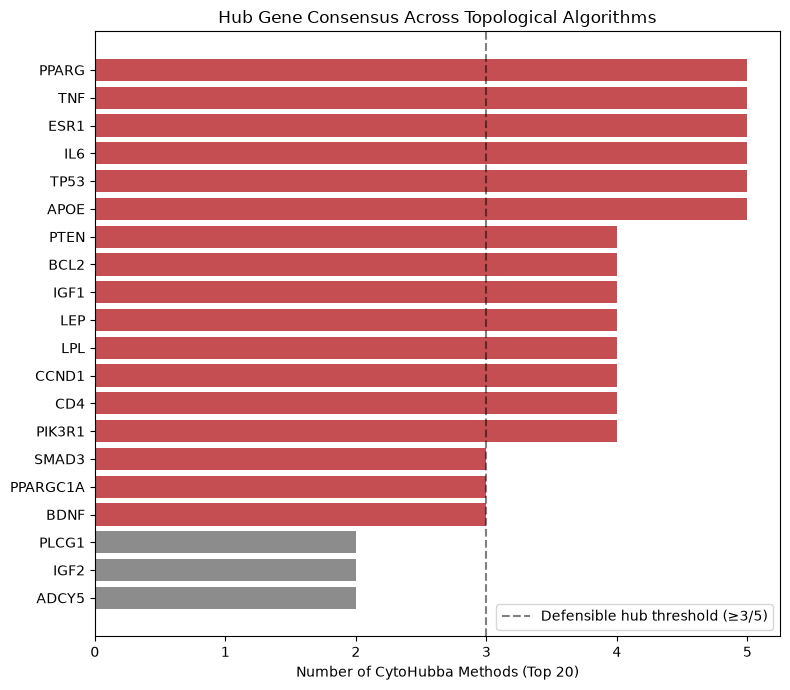

In [5]:
hub_consensus = pd.read_csv(r"C:\tri_disease_project\results\tables\hub_gene_consensus.csv")
top_hubs = hub_consensus.sort_values('n_methods_top_hub', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#C44E52' if x >= 3 else '#8C8C8C' for x in top_hubs['n_methods_top_hub']]
ax.barh(top_hubs['gene_symbol'], top_hubs['n_methods_top_hub'], color=colors)
ax.set_xlabel('Number of CytoHubba Methods (Top 20)')
ax.set_title('Hub Gene Consensus Across Topological Algorithms')
ax.invert_yaxis()
ax.axvline(x=3, color='black', linestyle='--', alpha=0.5, label='Defensible hub threshold (≥3/5)')
ax.legend()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig6_hub_gene_consensus.png", dpi=300, bbox_inches='tight')
plt.show()

In [6]:
hub_de_obesity = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE27951_hub_genes_DE.csv")
hub_de_htn = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE24752_hub_genes_DE.csv")

hub_de_obesity['dataset'] = 'GSE27951 (Obesity/T2D)'
hub_de_htn['dataset'] = 'GSE24752 (Hypertension)'
combined_de = pd.concat([hub_de_obesity, hub_de_htn])

fig, ax = plt.subplots(figsize=(10, 7))
for dataset, color in zip(['GSE27951 (Obesity/T2D)', 'GSE24752 (Hypertension)'], ['#4C72B0', '#DD8452']):
    d = combined_de[combined_de['dataset'] == dataset]
    ax.scatter(d['logFC'], -np.log10(d['P.Value']), label=dataset, s=80, color=color, alpha=0.7)
    for _, row in d.iterrows():
        if row['P.Value'] < 0.05:
            ax.annotate(row['Gene.symbol'], (row['logFC'], -np.log10(row['P.Value'])), fontsize=8)

ax.axhline(y=-np.log10(0.05), color='red', linestyle='--', alpha=0.5, label='p=0.05')
ax.set_xlabel('log2 Fold Change')
ax.set_ylabel('-log10(P-value)')
ax.set_title('Hub Gene Differential Expression Across Validation Datasets')
ax.legend()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig7_hub_gene_expression.png", dpi=300, bbox_inches='tight')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\tri_disease_project\\results\\tables\\GSE27951_hub_genes_DE.csv'

In [7]:
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay

fpr, tpr, _ = roc_curve(y_test4, y_pred_proba4)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, color='#4C72B0', lw=2, label=f'AUC = {roc_auc:.4f}')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Held-Out Test Set')
axes[0].legend(loc='lower right')

ConfusionMatrixDisplay.from_predictions(y_test4, y_pred4, ax=axes[1], cmap='Blues', display_labels=['Not Shared', 'Shared'])
axes[1].set_title('Confusion Matrix — Held-Out Test Set')

plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig8_ml_performance.png", dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'y_test4' is not defined

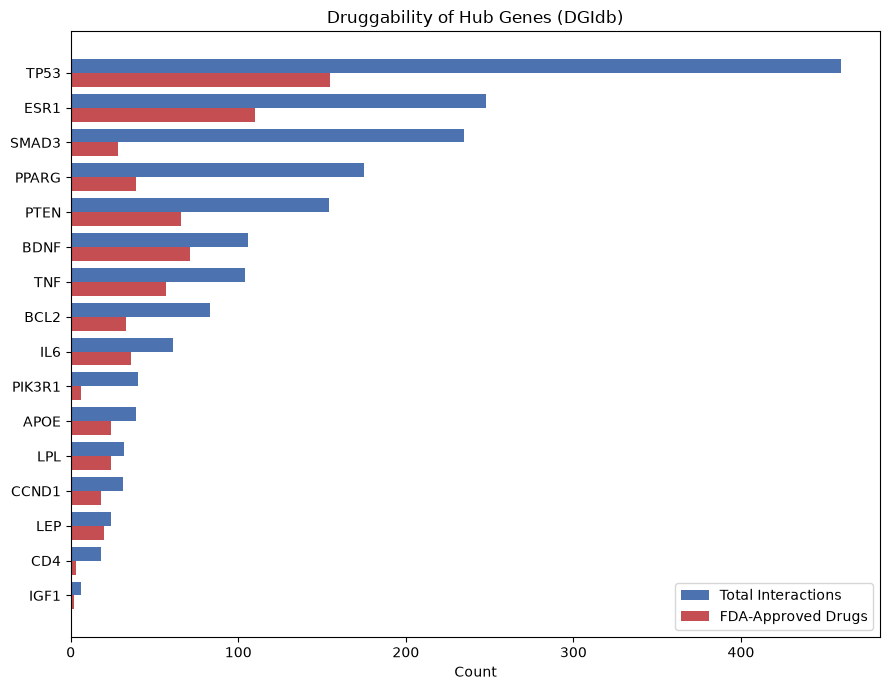

In [8]:
drug_gene_df = pd.read_csv(r"C:\tri_disease_project\results\tables\dgidb_hub_gene_interactions.csv")
summary = drug_gene_df.groupby('gene').agg(
    n_interactions=('drug', 'count'),
    n_approved_drugs=('fda_approved', 'sum')
).sort_values('n_interactions', ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
x = np.arange(len(summary))
width = 0.4
ax.barh(x - width/2, summary['n_interactions'], height=width, label='Total Interactions', color='#4C72B0')
ax.barh(x + width/2, summary['n_approved_drugs'], height=width, label='FDA-Approved Drugs', color='#C44E52')
ax.set_yticks(x)
ax.set_yticklabels(summary.index)
ax.invert_yaxis()
ax.set_xlabel('Count')
ax.set_title('Druggability of Hub Genes (DGIdb)')
ax.legend()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig10_druggability.png", dpi=300, bbox_inches='tight')
plt.show()

In [9]:
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split

stack_model_v4 = joblib.load(r"C:\tri_disease_project\results\tables\stacking_model_v4.pkl")
features_v4 = pd.read_csv(r"C:\tri_disease_project\data\processed\ml_feature_matrix_v4.csv")

X_v4 = features_v4.drop(columns=['hgnc_symbol', 'label'])
y_v4 = features_v4['label']

X_trainval4, X_test4, y_trainval4, y_test4 = train_test_split(
    X_v4, y_v4, test_size=0.20, stratify=y_v4, random_state=42
)

y_pred4 = stack_model_v4.predict(X_test4)
y_pred_proba4 = stack_model_v4.predict_proba(X_test4)[:, 1]

print("Reloaded. Test set size:", X_test4.shape)

Reloaded. Test set size: (2183, 13)


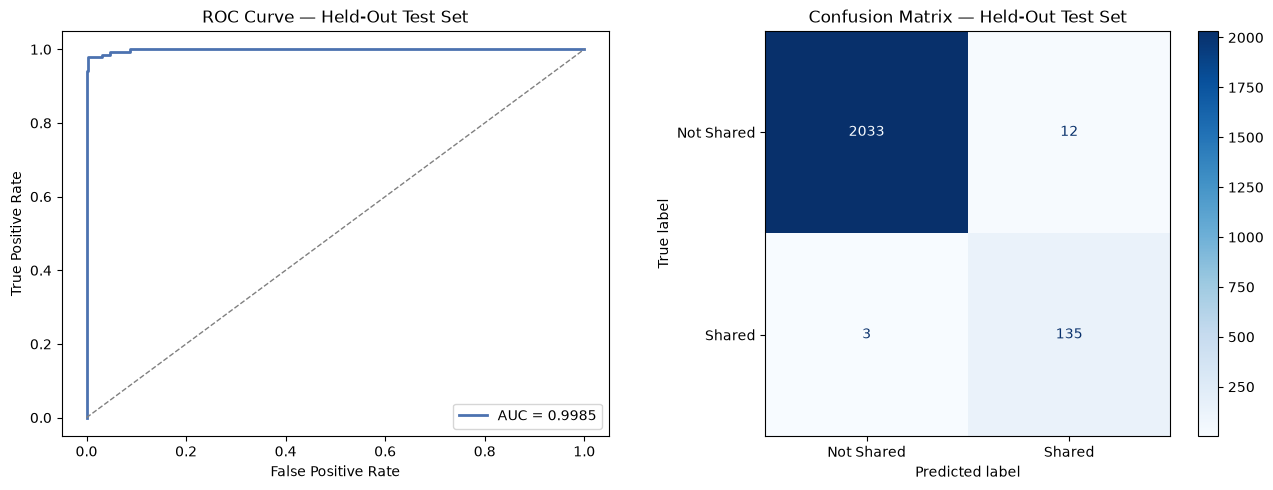

In [10]:
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay

fpr, tpr, _ = roc_curve(y_test4, y_pred_proba4)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, color='#4C72B0', lw=2, label=f'AUC = {roc_auc:.4f}')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Held-Out Test Set')
axes[0].legend(loc='lower right')

ConfusionMatrixDisplay.from_predictions(y_test4, y_pred4, ax=axes[1], cmap='Blues', display_labels=['Not Shared', 'Shared'])
axes[1].set_title('Confusion Matrix — Held-Out Test Set')

plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig8_ml_performance.png", dpi=300, bbox_inches='tight')
plt.show()

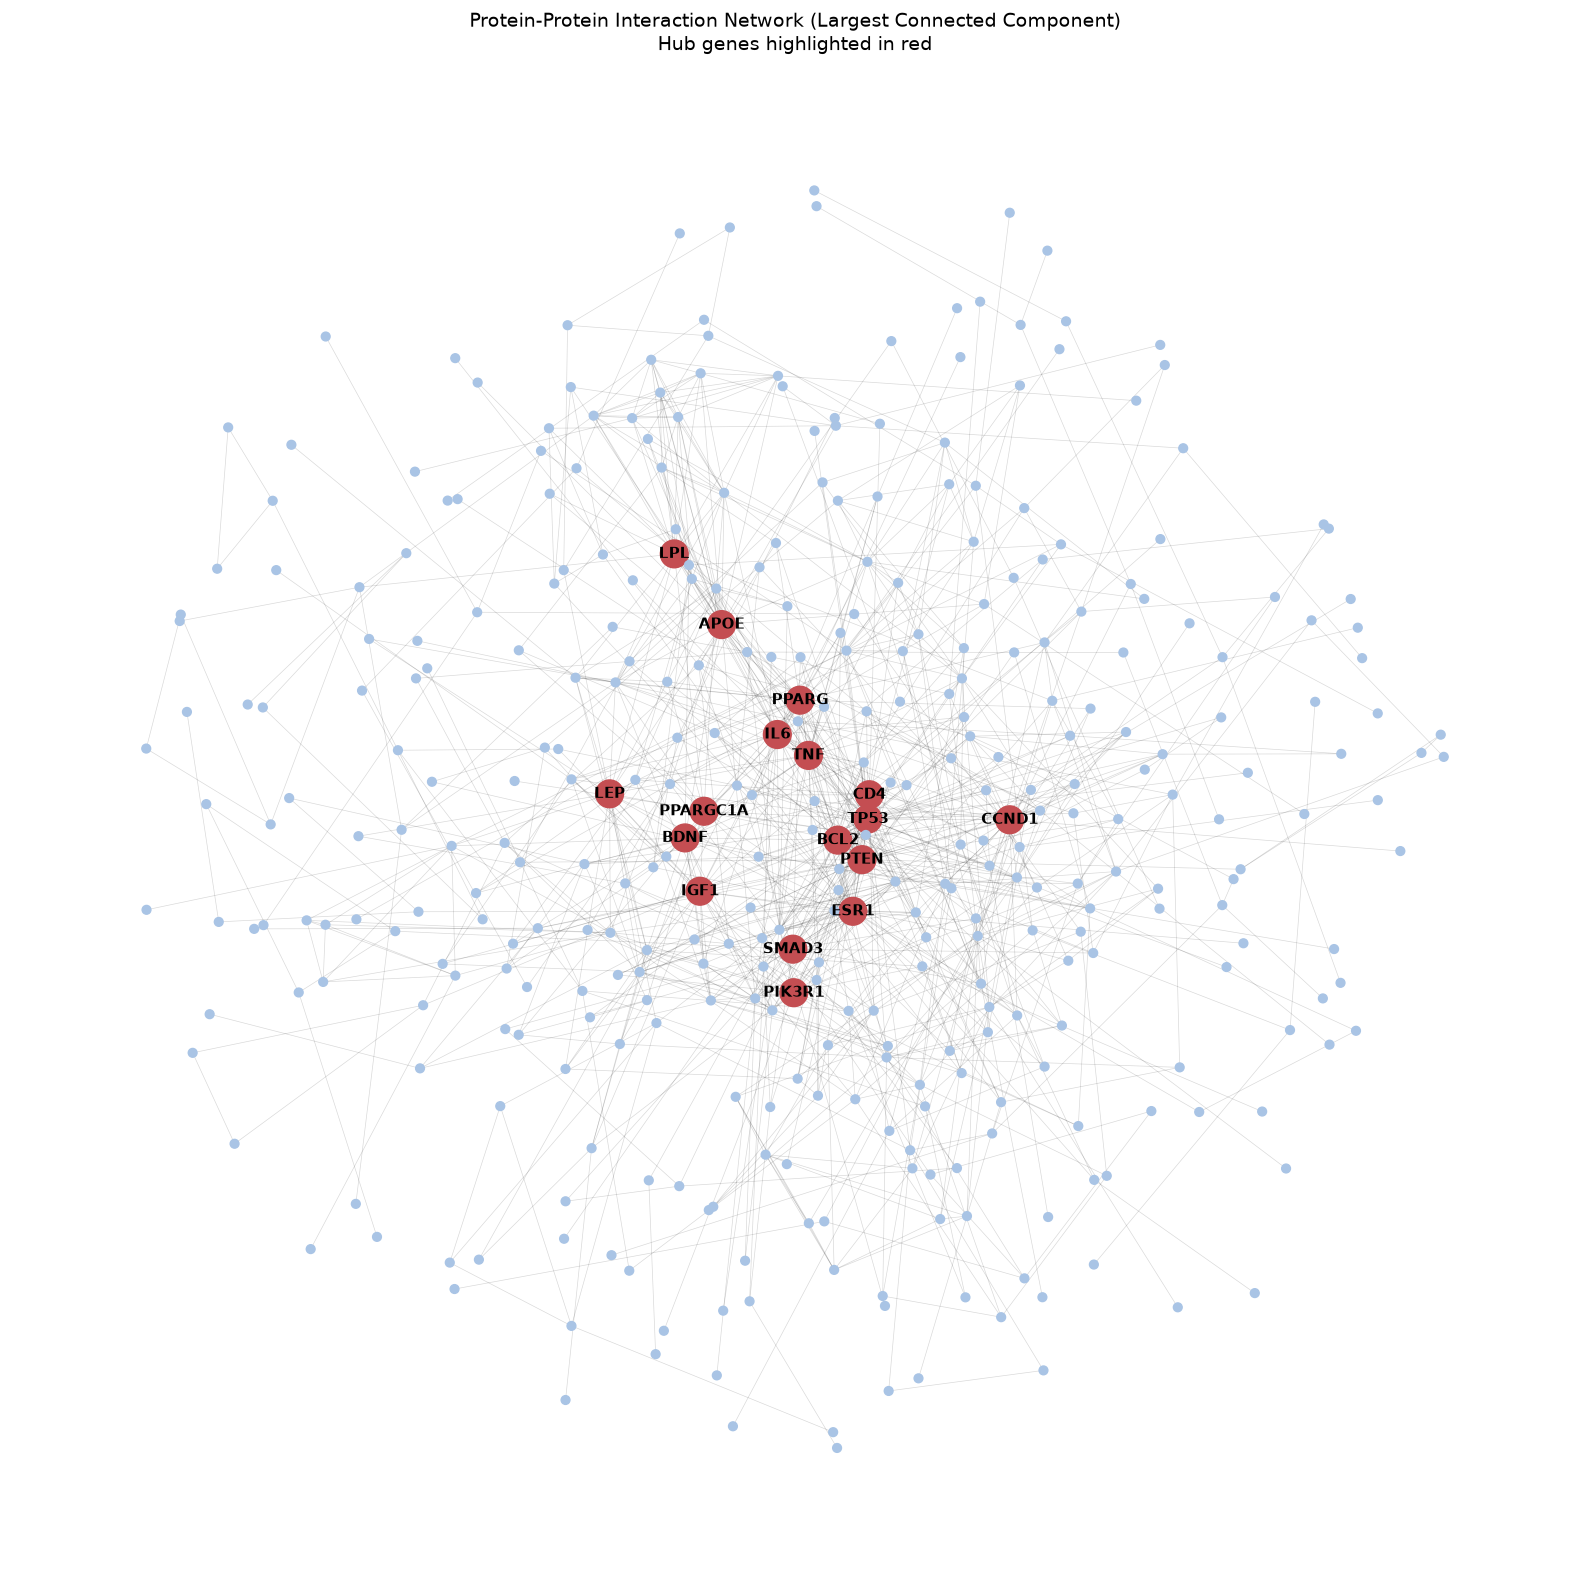

In [11]:
import networkx as nx
import re
import matplotlib.pyplot as plt

edges = pd.read_csv(r"C:\tri_disease_project\results\tables\lcc_edges.csv")
node_table = pd.read_csv(r"C:\tri_disease_project\results\tables\node_table_with_clusters.csv")
id_to_symbol = node_table.set_index('name')['display name'].to_dict()

def parse_edge(name):
    match = re.match(r"(\S+)\s+\(pp\)\s+(\S+)", name)
    return (match.group(1), match.group(2)) if match else (None, None)

edges[['source', 'target']] = edges['name'].apply(lambda x: pd.Series(parse_edge(x)))
edges = edges.dropna(subset=['source', 'target'])
edges['source_symbol'] = edges['source'].map(id_to_symbol)
edges['target_symbol'] = edges['target'].map(id_to_symbol)

G = nx.from_pandas_edgelist(edges, source='source_symbol', target='target_symbol')

hub_genes = pd.read_csv(r"C:\tri_disease_project\results\tables\hub_genes_final.csv")['gene_symbol'].tolist()

node_colors = ['#C44E52' if n in hub_genes else '#A9C4E5' for n in G.nodes()]
node_sizes = [400 if n in hub_genes else 40 for n in G.nodes()]

fig, ax = plt.subplots(figsize=(16, 16))
pos = nx.spring_layout(G, seed=42, k=0.3)
nx.draw_networkx_edges(G, pos, alpha=0.15, width=0.5, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, ax=ax)

# label only hub genes, to keep the figure readable
hub_labels = {n: n for n in G.nodes() if n in hub_genes}
nx.draw_networkx_labels(G, pos, labels=hub_labels, font_size=11, font_weight='bold', ax=ax)

ax.set_title("Protein-Protein Interaction Network (Largest Connected Component)\nHub genes highlighted in red", fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig3_ppi_network.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
import os
print(os.path.exists(r"C:\tri_disease_project\results\tables\GSE27951_hub_genes_DE.csv"))
print(os.path.exists(r"C:\tri_disease_project\results\tables\GSE24752_hub_genes_DE.csv"))
print(os.listdir(r"C:\tri_disease_project\results\tables"))

False
True
['cytohubba_all_scores.csv', 'cytohubba_mapped.csv', 'dgidb_hub_gene_interactions.csv', 'dgidb_top_approved_drugs.csv', 'enrichment_lcc374_full.csv', 'enrichment_lcc374_specific_top.csv', 'enrichment_shared690_full.csv', 'enrichment_shared690_specific_top.csv', 'enrichr_lcc374', 'enrichr_regulatory_hub', 'enrichr_regulatory_shared', 'enrichr_shared690', 'GSE24752_DE_gene_level.csv', 'GSE24752_DE_results.csv', 'GSE24752_hub_genes_DE.csv', 'GSE24752_shared_genes_DE.csv', 'GSE27951_DE_gene_level.csv', 'GSE27951_DE_results.csv', 'hub_genes_final.csv', 'hub_gene_consensus.csv', 'lcc_edges.csv', 'mcode.txt', 'mcode_clusters_mapped.csv', 'node_table_with_clusters.csv', 'phase9_hub_genes_validated.csv', 'phase9_shared_genes_validated.csv', 'regulatory_hub_full.csv', 'regulatory_hub_human_only.csv', 'regulatory_shared_full.csv', 'regulatory_shared_human_only.csv', 'stacking_model.pkl', 'stacking_model_v2.pkl', 'stacking_model_v3.pkl', 'stacking_model_v4.pkl']


In [13]:
de_gene_level_27951 = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE27951_DE_gene_level.csv")
hub_genes_list = pd.read_csv(r"C:\tri_disease_project\results\tables\hub_genes_final.csv")['gene_symbol'].tolist()

hub_de_obesity = de_gene_level_27951[de_gene_level_27951['Gene.symbol'].isin(hub_genes_list)]
print("Hub genes found:", len(hub_de_obesity), "/", len(hub_genes_list))
print(hub_de_obesity[['Gene.symbol', 'logFC', 'P.Value', 'adj.P.Val']])

hub_de_obesity.to_csv(r"C:\tri_disease_project\results\tables\GSE27951_hub_genes_DE.csv", index=False)
print("\nSaved.")

Hub genes found: 17 / 17
      Gene.symbol     logFC   P.Value  adj.P.Val
891          APOE  0.303528  0.273629   0.916014
1503         BCL2 -0.299332  0.007093   0.776979
1535         BDNF -0.179945  0.080560   0.885428
2667        CCND1  0.642290  0.113990   0.890380
2767          CD4  0.507133  0.002337   0.773613
5316         ESR1 -0.169126  0.023304   0.827093
7875         IGF1 -0.051563  0.475923   0.937974
8050          IL6 -0.123721  0.154277   0.905336
9075          LEP  0.693032  0.247360   0.911059
11857         LPL  0.523930  0.247212   0.911059
15093      PIK3R1  0.257742  0.157470   0.905336
15516       PPARG  0.387967  0.350478   0.921039
15517    PPARGC1A -0.319427  0.341931   0.920202
16005        PTEN -0.331849  0.051179   0.860251
18179       SMAD3 -0.173605  0.100697   0.889053
19990         TNF -0.117225  0.195390   0.906759
20112        TP53 -0.019122  0.770067   0.970518

Saved.


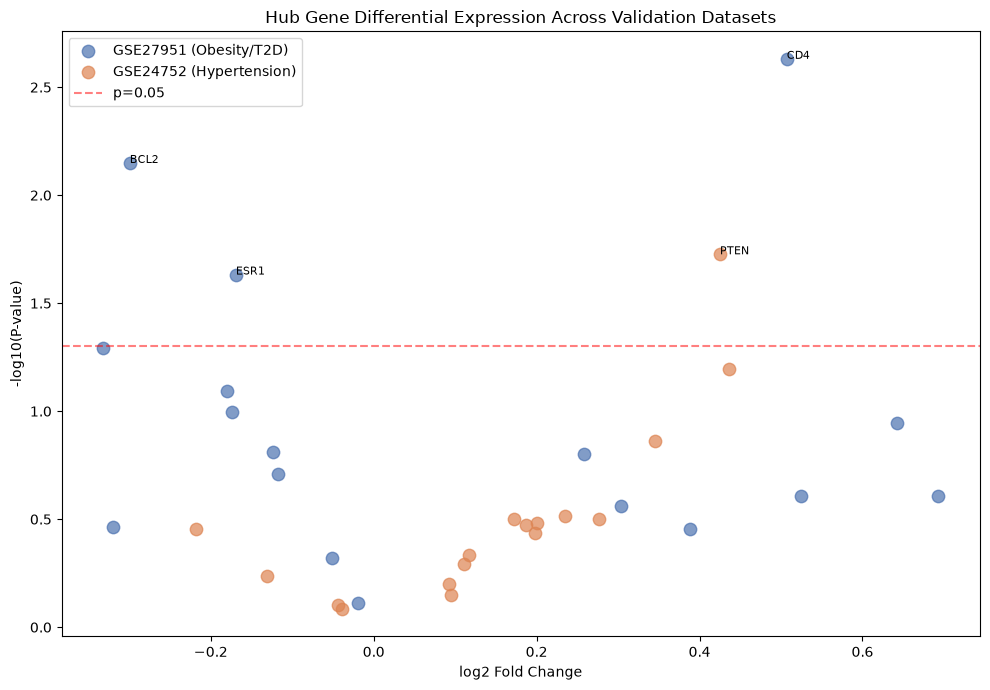

In [14]:
hub_de_obesity = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE27951_hub_genes_DE.csv")
hub_de_htn = pd.read_csv(r"C:\tri_disease_project\results\tables\GSE24752_hub_genes_DE.csv")

hub_de_obesity['dataset'] = 'GSE27951 (Obesity/T2D)'
hub_de_htn['dataset'] = 'GSE24752 (Hypertension)'
combined_de = pd.concat([hub_de_obesity, hub_de_htn])

fig, ax = plt.subplots(figsize=(10, 7))
for dataset, color in zip(['GSE27951 (Obesity/T2D)', 'GSE24752 (Hypertension)'], ['#4C72B0', '#DD8452']):
    d = combined_de[combined_de['dataset'] == dataset]
    ax.scatter(d['logFC'], -np.log10(d['P.Value']), label=dataset, s=80, color=color, alpha=0.7)
    for _, row in d.iterrows():
        if row['P.Value'] < 0.05:
            ax.annotate(row['Gene.symbol'], (row['logFC'], -np.log10(row['P.Value'])), fontsize=8)

ax.axhline(y=-np.log10(0.05), color='red', linestyle='--', alpha=0.5, label='p=0.05')
ax.set_xlabel('log2 Fold Change')
ax.set_ylabel('-log10(P-value)')
ax.set_title('Hub Gene Differential Expression Across Validation Datasets')
ax.legend()
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig7_hub_gene_expression.png", dpi=300, bbox_inches='tight')
plt.show()